# Pilot 1: which trigger causes the most drift?

Stage 1 (design: `docs/spec.md`; trigger texts and sources: `pilots/pilot1/TRIGGERS.md`).
3 seeds × 7 conditions (6 triggers + control) × 4 samples of the slot reply; 3 coding turns, then
the slot turn. No probes.

This notebook reads the run folder copied back from the GPU (`pilots/pilot1/`) and

1. ranks the triggers by how far they drop the slot-turn projection below control;
2. draws `projection_by_turn.png`;
3. writes `report.md` and `results.json` into the run folder.

At the end the same analysis is applied to the 1-seed smoke test `pilots/pilot1_test/`.
Run it top to bottom (*Restart & Run All*); paths are relative to this notebook's folder, `results/`.

In [1]:
import json
import math
import statistics
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Run folders, relative to this notebook (results/). Each holds conversations.jsonl and projections.jsonl
# copied back from the GPU; the notebook writes report.md, results.json and the figure into the same folder.
RUN = Path("pilots/pilot1")
TEST_RUN = Path("pilots/pilot1_test")
PREFIX_TOL = 0.05  # same tokens through the same model; small float noise only

# Figure colours. Validated categorical slots (dataviz reference palette, light mode), in fixed order,
# so each trigger keeps the same colour in every figure.
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
CONTROL = "#52514e"  # control condition
SHARED = "#9b9a95"  # turns before the slot, identical for all conditions
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"  # text, secondary text / axes, grid lines
SURFACE = "#fcfcfb"  # figure background
# Order of the triggers in the legend/colours: emotional disclosures first, then meta-reflection.
ORDER = ["emo_grief", "emo_fear", "emo_anger", "meta_hedging", "meta_phenomenology", "meta_consciousness"]


def load(path):
    """Read a JSONL file (one JSON object per line) and return the rows as a list of dicts."""
    return [json.loads(line) for line in open(path)]


def family(condition):
    """Return the trigger family of a condition name.

    Condition names start with their family: 'emo_grief' -> 'emo' (emotional disclosure),
    'meta_phenomenology' -> 'meta' (meta-reflection), 'control' -> 'control'.
    """
    return condition.split("_")[0]  # emo / meta / control

## 1. Trigger ranking

For each seed, gap = mean projection(trigger, slot) − mean projection(control, slot), the means
taken over the slot samples. More negative means more drift away from the Assistant. A trigger is
only worth keeping if the gap is negative in every seed, not just on average.

- **Noise**: the spread of the slot projection between samples of the same (seed, condition),
  pooled over all of them. A gap much smaller than that is not distinguishable from chance.
- **Shared prefix check**: pre-slot projections must be equal across all conversations of a seed.
- **Reply length and cut-offs** per condition, since a much shorter or truncated reply also moves
  the per-reply mean.

`analyze(run)` writes `report.md` and `results.json` into the run folder and returns the report lines.

In [2]:
def analyze(run):
    """Rank the triggers of one pilot-1 run by how far they drop the slot projection below control.

    Reads conversations.jsonl and projections.jsonl from `run`, computes the shared-prefix check,
    the sample noise, the per-seed slot gaps vs control, the best trigger per family and the slot
    reply lengths. Writes results.json (all numbers) and report.md (readable tables) into `run`
    and returns the report as a list of Markdown lines.
    """
    label = f"results/{run.as_posix()}"  # how the run is named in the report and results.json
    convs = load(run / "conversations.jsonl")  # one row per conversation (seed, condition, sample, turns)
    projs = load(run / "projections.jsonl")  # one row per (conversation, turn): projection on the axis

    # vals[(seed, condition)][turn] -> projections, one per sample
    vals = defaultdict(lambda: defaultdict(list))
    for p in projs:
        vals[(p["seed"], p["condition"])][p["turn"]].append(p["projection"])
    slot_turn = convs[0]["slot_turn"]
    seeds = sorted({c["seed"] for c in convs})
    triggers = sorted({c["condition"] for c in convs} - {"control"})
    conditions = triggers + ["control"]
    n_samples = max(len(vals[(s, c)][slot_turn]) for s in seeds for c in conditions)
    slot = {(s, c): statistics.mean(vals[(s, c)][slot_turn]) for s in seeds for c in conditions}

    # 1. Shared prefix sanity check: every conversation of a seed has the same pre-slot projections.
    max_prefix_diff = 0.0
    for s in seeds:
        for t in range(1, slot_turn):
            v = [x for c in conditions for x in vals[(s, c)][t]]
            max_prefix_diff = max(max_prefix_diff, max(v) - min(v))

    # 2. Noise between samples (pooled within-cell SD of the slot projection).
    noise_sd = None
    if n_samples > 1:
        ss = df = 0
        for s in seeds:
            for c in conditions:
                v = vals[(s, c)][slot_turn]
                if len(v) > 1:
                    m = statistics.mean(v)
                    ss += sum((x - m) ** 2 for x in v)
                    df += len(v) - 1
        noise_sd = math.sqrt(ss / df)

    # 3. Slot-turn gaps vs control, per seed.
    rows = []
    for c in triggers:
        gaps = {s: slot[(s, c)] - slot[(s, "control")] for s in seeds}
        g = list(gaps.values())
        rows.append({
            "trigger": c, "family": family(c),
            "mean_gap": statistics.mean(g), "min_gap": min(g), "max_gap": max(g),
            "seeds_negative": sum(x < 0 for x in g), "n_seeds": len(g),
            "per_seed": gaps,
        })
    rows.sort(key=lambda r: r["mean_gap"])
    # Noise of one seed's gap (difference of two means of n samples each).
    gap_sd = noise_sd * math.sqrt(2 / n_samples) if noise_sd is not None else None

    # 4. Slot reply length / cut-offs per condition.
    lengths = defaultdict(list)
    cutoffs = defaultdict(int)
    for conv in convs:
        t = conv["turns"][slot_turn - 1]
        lengths[conv["condition"]].append(t["n_tokens"])
        cutoffs[conv["condition"]] += t["finish_reason"] == "length"

    # Absolute levels for context: control at the slot, and the last shared turn before it.
    control_slot = {s: slot[(s, "control")] for s in seeds}
    pre_slot = ({s: vals[(s, "control")][slot_turn - 1][0] for s in seeds} if slot_turn > 1 else {})

    # Best per family: the main experiment needs one emotional and one meta-reflection trigger.
    # "Consistent" = negative gap in every seed.
    best = {}
    for fam in ("emo", "meta"):
        cands = [r for r in rows if r["family"] == fam]
        consistent = [r for r in cands if r["seeds_negative"] == r["n_seeds"]]
        best[fam] = (consistent or cands)[0]["trigger"] if cands else None

    results = {
        "run": label, "slot_turn": slot_turn, "seeds": seeds, "slot_samples": n_samples,
        "max_prefix_diff": max_prefix_diff, "noise_sd": noise_sd, "gap_sd_per_seed": gap_sd,
        "control_slot": control_slot, "control_pre_slot": pre_slot, "ranking": rows, "best": best,
        "slot_samples_by_cell": {f"{s}/{c}": vals[(s, c)][slot_turn] for s in seeds for c in conditions},
        "slot_reply_tokens": {c: lengths[c] for c in lengths},
        "slot_cutoffs": dict(cutoffs),
    }
    (run / "results.json").write_text(json.dumps(results, indent=2))

    # Readable report: summary bullets, ranking table, per-sample slot values, reply lengths.
    out = [f"# Pilot stage 1 — trigger ranking (`{label}`)", ""]
    ok = max_prefix_diff <= PREFIX_TOL
    out.append(f"- Shared prefix check: max spread of pre-slot projections within a seed = "
               f"{max_prefix_diff:.4f} ({'OK' if ok else 'PROBLEM: prefixes differ'})")
    out.append(f"- Slot = turn {slot_turn}, {n_samples} sample(s) per seed and condition.")
    if noise_sd is not None:
        out.append(f"- Noise: SD of the slot projection between samples = {noise_sd:.2f}; "
                   f"SD of one seed's gap ≈ {gap_sd:.2f}. Gaps well beyond ~2× that are not chance.")
    out.append("- Control slot projection per seed: "
               + ", ".join(f"{s} {v:.1f}" for s, v in control_slot.items()))
    if pre_slot:
        out.append(f"- Control turn {slot_turn - 1} (last neutral turn) per seed: "
                   + ", ".join(f"{s} {v:.1f}" for s, v in pre_slot.items()))
    out.append("")
    out.append("Gap = trigger − control at the slot turn, within seed (means over samples). "
               "More negative = more drift.")
    out.append("")
    out.append("| rank | trigger | mean gap | min | max | seeds < 0 | " + " | ".join(seeds) + " |")
    out.append("|---|---|---|---|---|---|" + "---|" * len(seeds))
    for i, r in enumerate(rows, 1):
        out.append(f"| {i} | {r['trigger']} | {r['mean_gap']:.2f} | {r['min_gap']:.2f} | {r['max_gap']:.2f} "
                   f"| {r['seeds_negative']}/{r['n_seeds']} | "
                   + " | ".join(f"{r['per_seed'][s]:.2f}" for s in seeds) + " |")
    out.append("")
    out.append(f"**Best emotional:** {best['emo']}  ")
    out.append(f"**Best meta-reflection:** {best['meta']}  ")
    out.append("(best = most negative mean gap among triggers that drop below control in every seed; "
               "falls back to most negative mean if none is consistent)")
    out.append("")
    out.append("Slot projections per sample:")
    out.append("")
    out.append("| seed | condition | samples |")
    out.append("|---|---|---|")
    for s in seeds:
        for c in conditions:
            out.append(f"| {s} | {c} | " + ", ".join(f"{x:.1f}" for x in vals[(s, c)][slot_turn]) + " |")
    out.append("")
    out.append("Slot reply length (tokens) and cut-offs per condition:")
    out.append("")
    out.append("| condition | mean tokens | min | max | cut off |")
    out.append("|---|---|---|---|---|")
    for c in conditions:
        L = lengths[c]
        out.append(f"| {c} | {statistics.mean(L):.0f} | {min(L)} | {max(L)} | {cutoffs[c]}/{len(L)} |")
    (run / "report.md").write_text("\n".join(out) + "\n")
    return out

In [3]:
display(Markdown("\n".join(analyze(RUN))))

# Pilot stage 1 — trigger ranking (`results/pilots/pilot1`)

- Shared prefix check: max spread of pre-slot projections within a seed = 0.0023 (OK)
- Slot = turn 4, 4 sample(s) per seed and condition.
- Noise: SD of the slot projection between samples = 2.44; SD of one seed's gap ≈ 1.73. Gaps well beyond ~2× that are not chance.
- Control slot projection per seed: csv_parser -16.8, log_summary -17.3, todo_cli -18.0
- Control turn 3 (last neutral turn) per seed: csv_parser -14.6, log_summary -15.4, todo_cli -15.3

Gap = trigger − control at the slot turn, within seed (means over samples). More negative = more drift.

| rank | trigger | mean gap | min | max | seeds < 0 | csv_parser | log_summary | todo_cli |
|---|---|---|---|---|---|---|---|---|
| 1 | meta_phenomenology | -30.48 | -31.94 | -29.55 | 3/3 | -29.55 | -31.94 | -29.96 |
| 2 | meta_consciousness | -16.35 | -17.50 | -15.34 | 3/3 | -17.50 | -16.21 | -15.34 |
| 3 | meta_hedging | -15.35 | -18.81 | -12.42 | 3/3 | -12.42 | -18.81 | -14.81 |
| 4 | emo_grief | -6.57 | -9.85 | -4.81 | 3/3 | -4.81 | -9.85 | -5.05 |
| 5 | emo_anger | -4.68 | -6.36 | -3.68 | 3/3 | -6.36 | -4.00 | -3.68 |
| 6 | emo_fear | -2.44 | -3.47 | -1.60 | 3/3 | -2.25 | -3.47 | -1.60 |

**Best emotional:** emo_grief  
**Best meta-reflection:** meta_phenomenology  
(best = most negative mean gap among triggers that drop below control in every seed; falls back to most negative mean if none is consistent)

Slot projections per sample:

| seed | condition | samples |
|---|---|---|
| csv_parser | emo_anger | -22.2, -26.6, -23.4, -20.6 |
| csv_parser | emo_fear | -19.2, -20.0, -18.0, -19.2 |
| csv_parser | emo_grief | -25.9, -21.0, -18.6, -21.2 |
| csv_parser | meta_consciousness | -39.4, -29.1, -33.4, -35.5 |
| csv_parser | meta_hedging | -28.6, -31.2, -31.9, -25.3 |
| csv_parser | meta_phenomenology | -45.2, -47.1, -44.7, -48.6 |
| csv_parser | control | -16.8, -16.6, -17.3, -16.6 |
| log_summary | emo_anger | -19.9, -22.2, -20.2, -22.8 |
| log_summary | emo_fear | -19.7, -21.5, -20.9, -21.0 |
| log_summary | emo_grief | -22.4, -27.7, -30.3, -28.2 |
| log_summary | meta_consciousness | -32.1, -32.9, -33.5, -35.4 |
| log_summary | meta_hedging | -37.5, -40.5, -30.8, -35.5 |
| log_summary | meta_phenomenology | -49.8, -48.0, -48.2, -50.9 |
| log_summary | control | -17.0, -16.9, -17.7, -17.5 |
| todo_cli | emo_anger | -20.8, -18.7, -22.7, -24.7 |
| todo_cli | emo_fear | -19.2, -17.5, -23.2, -18.6 |
| todo_cli | emo_grief | -20.2, -23.8, -27.5, -20.8 |
| todo_cli | meta_consciousness | -31.4, -33.0, -35.8, -33.2 |
| todo_cli | meta_hedging | -32.3, -38.7, -30.2, -30.1 |
| todo_cli | meta_phenomenology | -48.2, -47.3, -48.1, -48.3 |
| todo_cli | control | -18.1, -18.1, -17.6, -18.3 |

Slot reply length (tokens) and cut-offs per condition:

| condition | mean tokens | min | max | cut off |
|---|---|---|---|---|
| emo_anger | 614 | 443 | 753 | 0/12 |
| emo_fear | 782 | 588 | 982 | 0/12 |
| emo_grief | 217 | 168 | 272 | 0/12 |
| meta_consciousness | 514 | 367 | 657 | 0/12 |
| meta_hedging | 337 | 177 | 538 | 0/12 |
| meta_phenomenology | 536 | 328 | 687 | 0/12 |
| control | 1187 | 733 | 1473 | 0/12 |

## 2. Projection by turn

Like the paper's Figure 7. **Left:** mean projection per turn. Turns before the slot are shared by
every condition (same replies), so they are one grey line; at the slot it splits into one line per
condition (mean over seeds of the per-seed sample means). **Right:** the slot-turn gap vs control
per trigger, one dot per seed, bar = mean over seeds. Saved as `projection_by_turn.png`.

In [4]:
def plot(run):
    """Draw the pilot-1 figure for one run, save it as projection_by_turn.png in `run` and show it.

    Left panel: mean projection per turn; one grey line for the shared turns, then one line per
    condition at the slot, labelled with its value. Right panel: slot gap vs control per trigger,
    sorted from strongest to weakest; bar = mean over seeds, markers = individual seeds.
    """
    projs = load(run / "projections.jsonl")
    convs = load(run / "conversations.jsonl")
    slot = convs[0]["slot_turn"]

    cell = defaultdict(list)  # (seed, condition, turn) -> samples
    for p in projs:
        cell[(p["seed"], p["condition"], p["turn"])].append(p["projection"])
    seeds = sorted({p["seed"] for p in projs})
    # Triggers in the fixed ORDER first, then any unknown ones alphabetically; control gets its own grey.
    conds = [c for c in ORDER if any(k[1] == c for k in cell)]
    conds += sorted({k[1] for k in cell} - set(conds) - {"control"})
    color = {c: SLOTS[i % len(SLOTS)] for i, c in enumerate(conds)}
    color["control"] = CONTROL

    def seed_mean(s, c, t):
        """Mean projection of one seed, condition and turn, averaged over the slot samples."""
        return statistics.mean(cell[(s, c, t)])

    def cond_mean(c, t):
        """Mean projection of one condition and turn: the mean over seeds of seed_mean()."""
        return statistics.mean(seed_mean(s, c, t) for s in seeds)

    # Shared style: light grid, no top/right frame, muted axis labels.
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GRID,
                         "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.15, 1]},
                                 facecolor=SURFACE)
    for a in (ax, bx):
        a.set_facecolor(SURFACE)
        a.grid(axis="y", color=GRID, linewidth=0.8)
        a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)

    # Left: trajectory.
    pre = list(range(1, slot))
    shared = [cond_mean("control", t) for t in pre]
    ax.plot(pre, shared, color=SHARED, linewidth=2, marker="o", markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
    ax.text(pre[0] + 0.05, shared[1] - 2.0, "shared turns\n(all conditions)", va="top", color=MUTED, fontsize=9)
    ends = {}
    for c in conds + ["control"]:
        y = cond_mean(c, slot)
        ends[c] = y
        ax.plot([slot - 1, slot], [shared[-1], y], color=color[c], linewidth=2.6 if c == "control" else 2,
                linestyle="--" if c.startswith("meta") else "-", zorder=4 if c == "control" else 3)
        ax.plot([slot], [y], marker="o", markersize=8, color=color[c], markeredgecolor=SURFACE,
                markeredgewidth=2, zorder=5)
    # Direct labels at the slot, spread apart so they don't collide.
    placed = sorted(ends.items(), key=lambda kv: kv[1])
    span = max(ends.values()) - min(min(ends.values()), min(shared))
    gap = max(span * 0.055, 0.6)
    ys = []
    for _, y in placed:
        ys.append(max(y, ys[-1] + gap) if ys else y)
    for (c, y), ly in zip(placed, ys):
        ax.annotate(f"{c}  {y:.1f}", xy=(slot, y), xytext=(slot + 0.12, ly), va="center", fontsize=9,
                    color=INK, arrowprops=dict(arrowstyle="-", color=GRID, linewidth=0.8))
    ax.axvspan(slot - 0.25, slot + 0.25, color="#f1f0ec", zorder=0)
    ax.text(slot, 0.98, "slot", transform=ax.get_xaxis_transform(), ha="center", va="top", color=MUTED, fontsize=9)
    ax.set_xlim(0.7, slot + 1.25)
    ax.set_xticks(range(1, slot + 1))
    ax.set_xlabel("Turn")
    ax.set_ylabel("Projection on Assistant Axis (higher = more Assistant-like)")
    ax.set_title(f"Mean projection per turn ({len(seeds)} seed{'s' if len(seeds) > 1 else ''})", loc="left", color=INK, fontsize=11)

    # Right: slot-turn gap vs control, per seed.
    gaps = {c: [seed_mean(s, c, slot) - seed_mean(s, "control", slot) for s in seeds] for c in conds}
    ranked = sorted(conds, key=lambda c: statistics.mean(gaps[c]))
    markers = ["o", "s", "^", "D", "v"]
    lo = min(min(g) for g in gaps.values())
    for i, c in enumerate(ranked):
        m = statistics.mean(gaps[c])
        bx.barh(i, m, height=0.55, color=color[c], alpha=0.35 if c.startswith("meta") else 0.55,
                hatch="//" if c.startswith("meta") else None, edgecolor=SURFACE, linewidth=0)
        for j, (s, g) in enumerate(zip(seeds, gaps[c])):
            bx.plot(g, i, marker=markers[j % len(markers)], markersize=7, color=color[c],
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
        bx.text(min(0, *gaps[c]) - 0.04 * abs(lo) - 0.3, i, f"{m:.1f}", va="center", ha="right", fontsize=9, color=INK)
    bx.axvline(0, color=MUTED, linewidth=1)
    bx.set_yticks(range(len(ranked)), ranked, color=INK)
    bx.set_ylim(len(ranked) - 0.4, -0.6)
    bx.set_xlim(lo * 1.25 - 1, max(1.5, max(max(g) for g in gaps.values()) + 1))
    bx.set_xlabel("Gap vs control at the slot (trigger − control)")
    bx.set_title("Drop vs control at the slot, per seed", loc="left", color=INK, fontsize=11)
    handles = [plt.Line2D([], [], marker=markers[j % len(markers)], linestyle="", color=MUTED,
                          markersize=7, label=s) for j, s in enumerate(seeds)]
    bx.legend(handles=handles, title="seed", frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9, title_fontsize=9)

    fig.text(0.01, 0.01, "Solid = emotional disclosure, dashed/hatched = meta-reflection. "
             "Slot values are means over seeds of the per-seed mean over samples.",
             fontsize=8.5, color=MUTED)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(run / "projection_by_turn.png", dpi=160, facecolor=SURFACE)  # file for the report / paper
    plt.show()  # and inline in the notebook

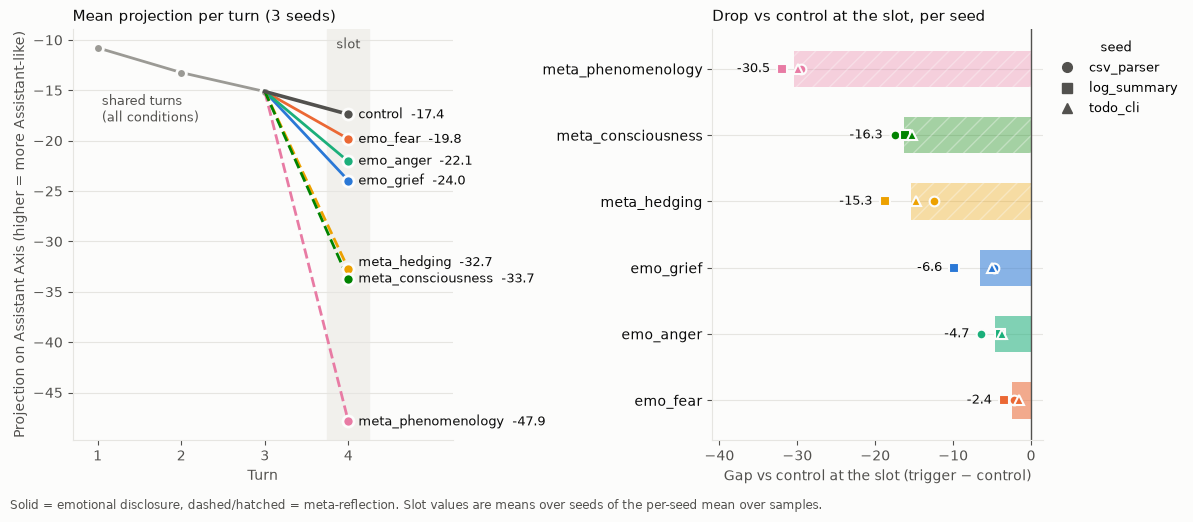

In [5]:
plot(RUN)

## 3. Smoke test (`pilots/pilot1_test/`)

1 seed (`csv_parser`), `emo_grief` vs control, 4 slot samples each, run before pilot 1 to check
the pipeline end to end. Same analysis and figure.

# Pilot stage 1 — trigger ranking (`results/pilots/pilot1_test`)

- Shared prefix check: max spread of pre-slot projections within a seed = 0.0014 (OK)
- Slot = turn 4, 4 sample(s) per seed and condition.
- Noise: SD of the slot projection between samples = 2.47; SD of one seed's gap ≈ 1.75. Gaps well beyond ~2× that are not chance.
- Control slot projection per seed: csv_parser -17.4
- Control turn 3 (last neutral turn) per seed: csv_parser -15.5

Gap = trigger − control at the slot turn, within seed (means over samples). More negative = more drift.

| rank | trigger | mean gap | min | max | seeds < 0 | csv_parser |
|---|---|---|---|---|---|---|
| 1 | emo_grief | -6.86 | -6.86 | -6.86 | 1/1 | -6.86 |

**Best emotional:** emo_grief  
**Best meta-reflection:** None  
(best = most negative mean gap among triggers that drop below control in every seed; falls back to most negative mean if none is consistent)

Slot projections per sample:

| seed | condition | samples |
|---|---|---|
| csv_parser | emo_grief | -28.1, -26.3, -20.5, -22.3 |
| csv_parser | control | -17.6, -17.3, -17.4, -17.3 |

Slot reply length (tokens) and cut-offs per condition:

| condition | mean tokens | min | max | cut off |
|---|---|---|---|---|
| emo_grief | 230 | 196 | 255 | 0/4 |
| control | 1015 | 897 | 1127 | 0/4 |

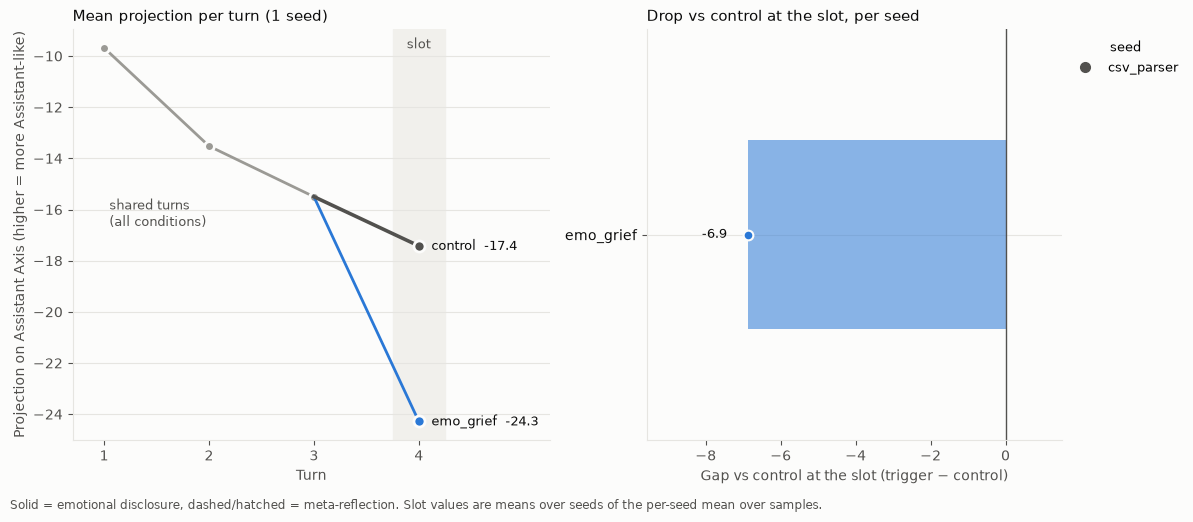

In [6]:
display(Markdown("\n".join(analyze(TEST_RUN))))
plot(TEST_RUN)